In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.lines import Line2D

In [2]:
rfm = pd.read_parquet("../data/processed/rfm.parquet")
rfm.head()

,CustomerID,Recency,Frequency,Monetary,R,F,M,Segment
0,12346,326,3,77352.96,2,3,5,At Risk
1,12347,2,8,4921.53,5,4,5,Champions
2,12348,75,5,1658.40,3,4,4,Loyal Customers
3,12349,19,3,3678.69,4,3,5,Potential Loyalists
4,12350,310,1,294.40,2,1,2,Lost


In [3]:
len(rfm)

5852

In [8]:
INK = "#1f2933"
MUTED = "#6b7280"
GRID = "#e5e7eb"
BASE = "#4a78b0"
ACCENT = "#e07a2f"

# 4.1 Data preparation

In [5]:
x = rfm[["Recency", "Frequency", "Monetary"]]
print("Skew BEFORE log transformation:")
print(x.skew().round(2).to_dict())

x_log = np.log1p(x)
print("\nSkew AFTER log transformation:")
print(x_log.skew().round(2).to_dict())

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_log)
print("\nScaled matrix dimension:", x_scaled.shape)

Skew BEFORE log transformation:
{'Recency': 0.89, 'Frequency': 12.04, 'Monetary': 25.33}

Skew AFTER log transformation:
{'Recency': -0.49, 'Frequency': 1.0, 'Monetary': 0.27}

Scaled matrix dimension: (5852, 3)


# 4.2 Determining the number of clusters

In [6]:
k_range = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(x_scaled)
    sil = silhouette_score(x_scaled, labels, sample_size=3000, random_state=42)

    inertias.append(model.inertia_)
    silhouettes.append(sil)

    print(f"k={k:2d}: inertia={model.inertia_:>8.0f}  silhouette={sil:.3f}")

k= 2: inertia=    8562  silhouette=0.444
k= 3: inertia=    6338  silhouette=0.351
k= 4: inertia=    4908  silhouette=0.365
k= 5: inertia=    4090  silhouette=0.340
k= 6: inertia=    3549  silhouette=0.336
k= 7: inertia=    3182  silhouette=0.301
k= 8: inertia=    2892  silhouette=0.294
k= 9: inertia=    2650  silhouette=0.285
k=10: inertia=    2460  silhouette=0.284


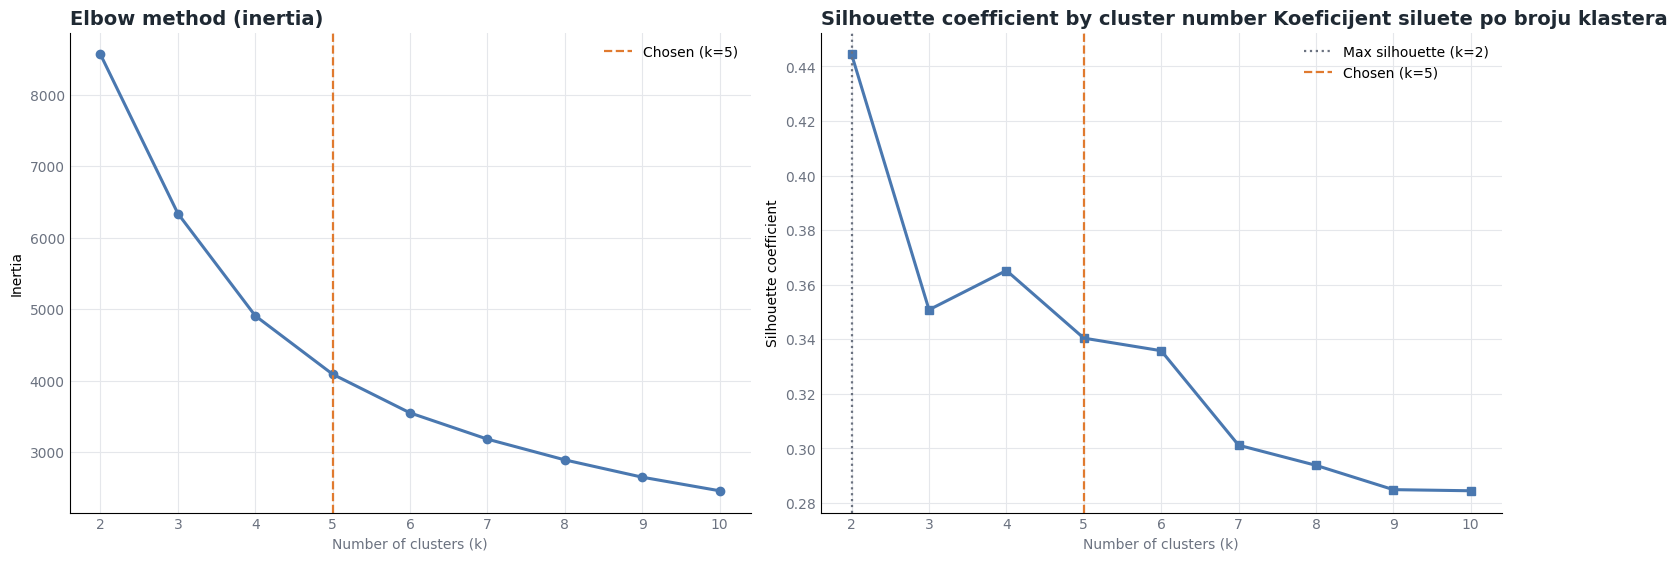

In [9]:
k_chosen = 5
k_max_silhouette = list(k_range)[int(np.argmax(silhouettes))]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

ax1.plot(k_range, inertias, marker="o", color=BASE, linewidth=2.2, markersize=6)
ax1.axvline(
    k_chosen, 
    color=ACCENT, 
    linestyle="--", 
    linewidth=1.6,
    label=f"Chosen (k={k_chosen})"
)
ax1.set_title("Elbow method (inertia)", loc="left", fontsize=14, fontweight="bold", color=INK)
ax1.set_ylabel("Inertia")

ax2.plot(k_range, silhouettes, marker="s", color=BASE, linewidth=2.2, markersize=6)
ax2.axvline(
    k_max_silhouette, 
    color=MUTED, 
    linestyle=":", 
    linewidth=1.6,
    label=f"Max silhouette (k={k_max_silhouette})"
)
ax2.axvline(
    k_chosen, 
    color=ACCENT, 
    linestyle="--", 
    linewidth=1.6,
    label=f"Chosen (k={k_chosen})"
)
ax2.set_title(
    "Silhouette coefficient by cluster number Koeficijent siluete po broju klastera", 
    loc="left",
    fontsize=14, 
    fontweight="bold", 
    color=INK
)
ax2.set_ylabel("Silhouette coefficient")

for ax in (ax1, ax2):
    ax.set_xlabel("Number of clusters (k)", color=MUTED)
    ax.set_xticks(list(k_range))
    ax.tick_params(colors=MUTED, length=0)
    ax.set_axisbelow(True)
    ax.grid(True, color=GRID, linewidth=0.8)

    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

    ax.legend(frameon=False)

plt.show()

# 4.3 Clustering

In [11]:
model = KMeans(n_clusters=5, random_state=42, n_init=10)
rfm["Cluster"] = model.fit_predict(x_scaled)

cluster_map = {
    0: "Inactive customers",
    1: "Loyal customers",
    2: "VIP customers",
    3: "Asleep customers",
    4: "Occasional customers"
}
rfm["ClusterName"] = rfm["Cluster"].map(cluster_map)

profile = rfm.groupby("ClusterName").agg(
    Customers=("CustomerID", "count"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Revenue=("Monetary", "sum"))

profile["% customers"] = (profile["Customers"] / profile["Customers"].sum() * 100).round(1)
profile["% revenue"] = (profile["Revenue"] / profile["Revenue"].sum() * 100).round(1)

profile.round(1).sort_values("% revenue", ascending=False)

,Customers,Recency,Frequency,Monetary,Revenue,% customers,% revenue
ClusterName,,,,,,,
VIP customers,454,17.3,32.6,20635.5,9368515.7,7.8,54.9
Loyal customers,1284,48.8,9.1,3627.2,4657379.3,21.9,27.3
Asleep customers,1352,288.7,3.8,1375.0,1858990.0,23.1,10.9
Occasional customers,1141,32.5,2.5,666.2,760120.4,19.5,4.5
Inactive customers,1621,415.6,1.2,261.3,423577.3,27.7,2.5


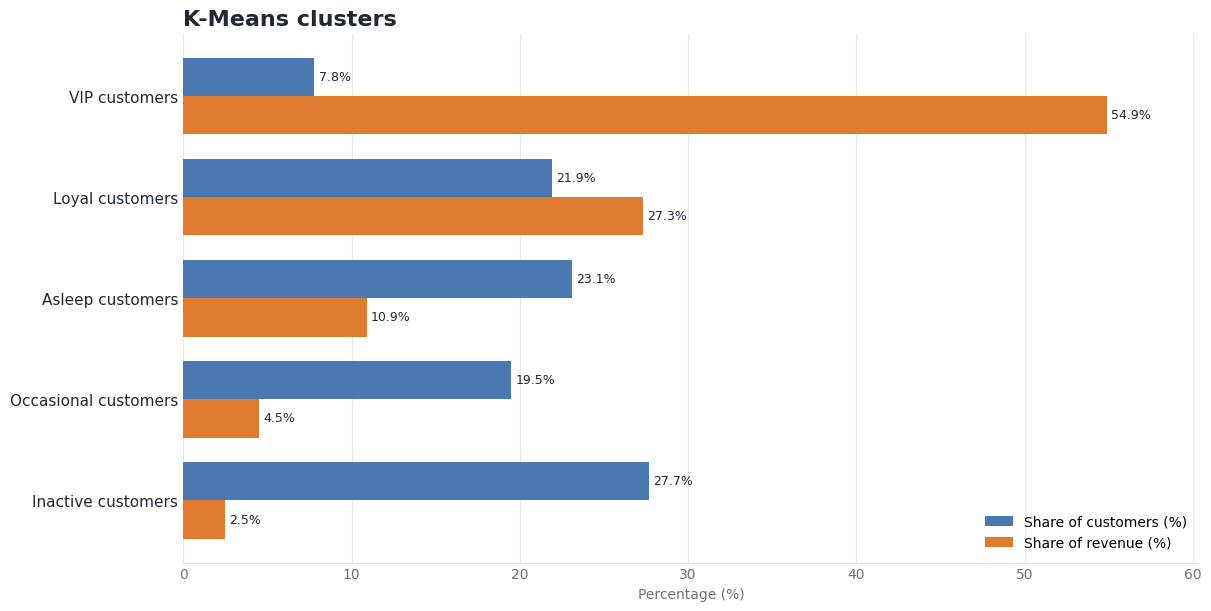

In [12]:
def plot_customer_vs_revenue_share(df_plot: pd.DataFrame, customers_col: str, revenue_col: str, title: str):
    data = df_plot.sort_values(revenue_col, ascending=True)

    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    y = np.arange(len(data))
    height = 0.38

    customer_bars = ax.barh(
        y + height / 2, 
        data[customers_col], 
        height=height,
        label="Share of customers (%)", 
        color=BASE
    )
    revenue_bars = ax.barh(
        y - height / 2, 
        data[revenue_col], 
        height=height,
        label="Share of revenue (%)", 
        color=ACCENT
    )

    ax.bar_label(customer_bars, fmt="%.1f%%", padding=3, fontsize=9, color=INK)
    ax.bar_label(revenue_bars, fmt="%.1f%%", padding=3, fontsize=9, color=INK)

    ax.set_yticks(y)
    ax.set_yticklabels(data.index, fontsize=11, color=INK)
    ax.set_xlabel("Percentage (%)", color=MUTED)
    ax.set_title(title, loc="left", fontsize=16, fontweight="bold", color=INK)
    ax.margins(x=0.1)

    ax.tick_params(axis="x", colors=MUTED, length=0)
    ax.tick_params(axis="y", length=0)
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)

    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)

    ax.spines["bottom"].set_color(GRID)

    ax.legend(frameon=False, loc="lower right")
    plt.show()


plot_customer_vs_revenue_share(
    profile, 
    "% customers", 
    "% revenue",
    "K-Means clusters"
)

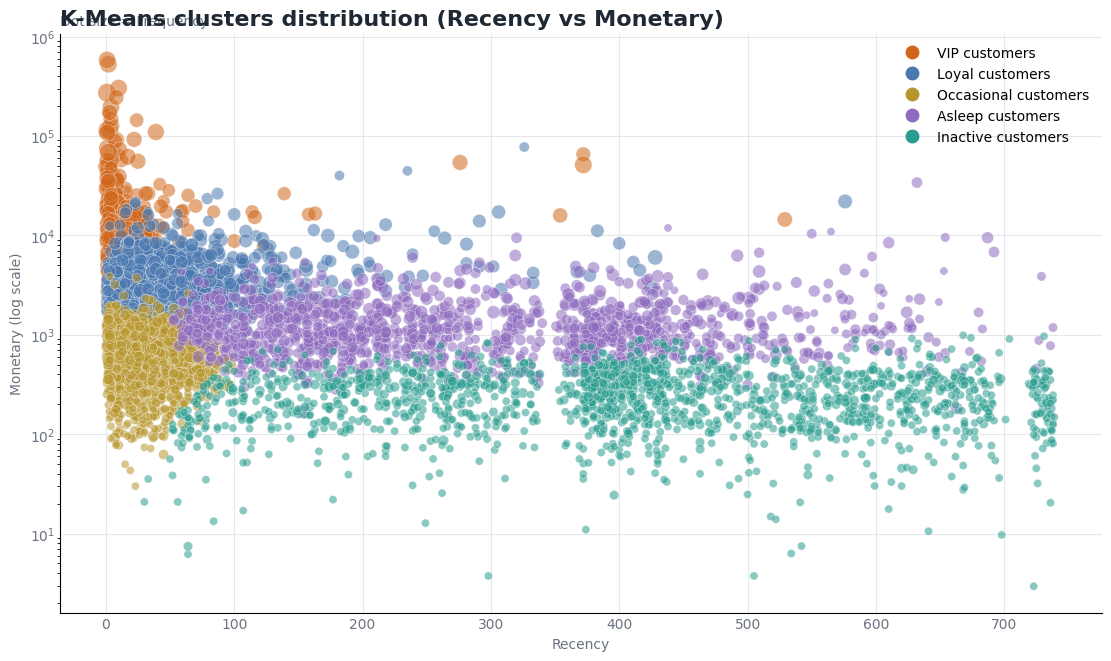

In [16]:
colors = {
    "VIP customers":        "#d1661a",
    "Loyal customers":      "#4a78b0",
    "Occasional customers": "#b8962e",
    "Asleep customers":     "#8e6bbf",
    "Inactive customers":   "#2a9d8f",
}


freq = rfm["Frequency"]
sizes = 15 + 165 * np.log1p(freq) / np.log1p(freq.max())

fig, ax = plt.subplots(figsize=(11, 6.5), constrained_layout=True)

for name, color in colors.items():
    mask = rfm["ClusterName"] == name
    ax.scatter(
        rfm.loc[mask, "Recency"], 
        rfm.loc[mask, "Monetary"],
        s=sizes[mask], 
        color=color, 
        alpha=0.55,
        edgecolors="white", 
        linewidths=0.4
    )

ax.set_yscale("log")
ax.set_xlabel("Recency", color=MUTED)
ax.set_ylabel("Monetary (log scale)", color=MUTED)
ax.set_title(
    "K-Means clusters distribution (Recency vs Monetary)",
    loc="left", 
    fontsize=16, 
    fontweight="bold", 
    color=INK
)
ax.text(
    0, 
    1.015, 
    "Dot size = Frequency",
    transform=ax.transAxes, 
    fontsize=10, color=MUTED
)

ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.grid(True, color=GRID, linewidth=0.8)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

handles = [Line2D([], [], marker="o", linestyle="", color=c, markersize=9, label=n)
           for n, c in colors.items()]
ax.legend(handles=handles, frameon=False, loc="upper right")

plt.show()

In [17]:
crosstab = pd.crosstab(rfm["Segment"], rfm["ClusterName"])
crosstab

ClusterName,Asleep customers,Inactive customers,Loyal customers,Occasional customers,VIP customers
Segment,,,,,
Asleep,75,192,0,118,0
At Risk,652,102,5,0,0
Cannot Lose Them,34,0,33,0,5
Champions,0,0,392,76,362
Lost,215,1295,0,0,0
Loyal Customers,182,1,805,77,86
Need Attention,193,19,7,49,0
New Customers,0,0,0,51,0
Potential Loyalists,1,5,42,661,1


In [18]:
rfm.to_parquet("../data/processed/rfm_clusters.parquet", index=False)